<a href="https://colab.research.google.com/github/RaniaChaudhry511/CODE-ALPHA-INTERNSHIP/blob/main/CodeAlpha_Handwritten_Character_Recognition.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

# Task 3: Handwritten Character Recognition (MNIST + CNN)

**CodeAlpha Machine Learning Internship**

## Project Introduction

**Objective:** Recognize handwritten digits (0 to 9). Given an image of a handwritten digit, the model predicts which digit it is.

**Dataset:** MNIST
- 70,000 grayscale images, each 28x28 pixels
- 60,000 training images and 10,000 test images
- 10 classes (digits 0 to 9)

**Model:** Convolutional Neural Network (CNN)
- A CNN learns patterns such as edges, curves and shapes on its own, which makes it a strong choice for image recognition.

**Tools:** Python, TensorFlow/Keras, NumPy, Matplotlib, Google Colab

## Project Steps

1. Load and understand the dataset
2. Visualize sample images
3. Data preprocessing (normalize and reshape)
4. Build the CNN model
5. Train the model
6. Evaluate on test data
7. Make predictions and summarize results

## Step 1: Load the MNIST Dataset

MNIST is built into Keras, so there is no need to download or upload any file. In this step we will:
- Import the required libraries
- Load the dataset
- Check its shape, pixel range and labels

In [1]:
import numpy as np
import matplotlib.pyplot as plt
import tensorflow as tf
from tensorflow import keras

print("TensorFlow version:", tf.__version__)

(x_train, y_train), (x_test, y_test) = keras.datasets.mnist.load_data()

print("x_train shape:", x_train.shape)
print("y_train shape:", y_train.shape)
print("x_test shape:", x_test.shape)
print("y_test shape:", y_test.shape)
print("Pixel value range:", x_train.min(), "to", x_train.max())
print("Unique labels:", np.unique(y_train))

TensorFlow version: 2.21.0
11490434/11490434 ━━━━━━━━━━━━━━━━━━━━ 0s 0us/step
x_train shape: (60000, 28, 28)
y_train shape: (60000,)
x_test shape: (10000, 28, 28)
y_test shape: (10000,)
Pixel value range: 0 to 255
Unique labels: [0 1 2 3 4 5 6 7 8 9]


### Observation

- The dataset loaded successfully. TensorFlow version is 2.21.0.
- **x_train shape (60000, 28, 28):** 60,000 training images, each 28x28 pixels.
- **x_test shape (10000, 28, 28):** 10,000 test images of the same size.
- **y_train and y_test:** one label (digit) per image, so 60,000 and 10,000 labels.
- **Pixel value range 0 to 255:** 0 is black and 255 is white. We will normalize this to the 0 to 1 range during preprocessing so the CNN trains better.
- **Unique labels 0 to 9:** there are 10 classes, so this is a 10-class classification problem.
- The images currently have no channel dimension. A CNN expects shape (28, 28, 1), which we will fix in the preprocessing step.

## Step 2: Visualize Sample Images

Before building a model, we should look at our data. In this step we will:
- View the first 10 training images with their labels
- Check how many samples each digit has, to see whether the classes are balanced

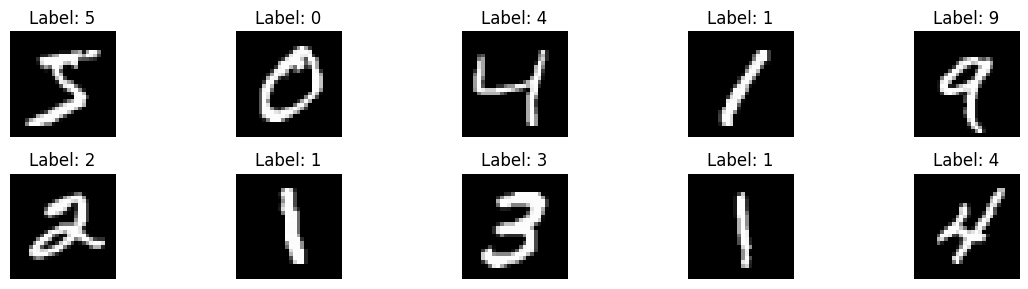

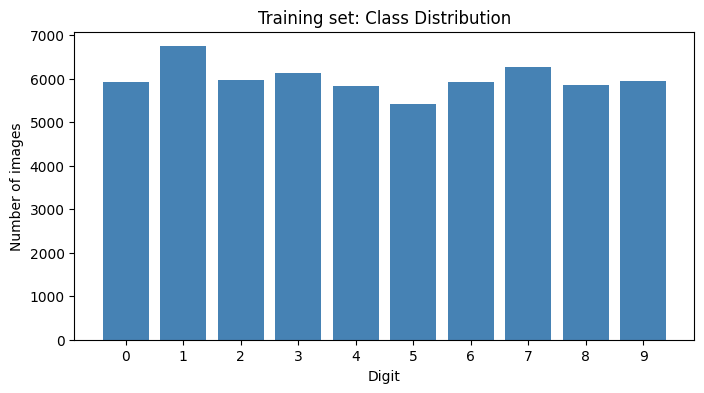

{np.uint8(0): np.int64(5923), np.uint8(1): np.int64(6742), np.uint8(2): np.int64(5958), np.uint8(3): np.int64(6131), np.uint8(4): np.int64(5842), np.uint8(5): np.int64(5421), np.uint8(6): np.int64(5918), np.uint8(7): np.int64(6265), np.uint8(8): np.int64(5851), np.uint8(9): np.int64(5949)}


In [2]:
# Pehli 10 images unke labels ke saath
plt.figure(figsize=(12, 3))
for i in range(10):
    plt.subplot(2, 5, i + 1)
    plt.imshow(x_train[i], cmap='gray')
    plt.title(f"Label: {y_train[i]}")
    plt.axis('off')
plt.tight_layout()
plt.show()

# Har digit ke kitne samples hain
digits, counts = np.unique(y_train, return_counts=True)
plt.figure(figsize=(8, 4))
plt.bar(digits, counts, color='steelblue')
plt.xticks(digits)
plt.xlabel("Digit")
plt.ylabel("Number of images")
plt.title("Training set: Class Distribution")
plt.show()

print(dict(zip(digits, counts)))

### Observation

- The first 10 images show the digits 5, 0, 4, 1, 9, 2, 1, 3, 1, 4, and each label matches its image.
- The images are white handwriting on a black background. Every writer has a different style (for example the shapes of "4" and "2"), so the CNN has to learn from these variations.
- In the class distribution graph, each digit has roughly 5,400 to 6,700 samples. Digit 1 has the most (6,742) and digit 5 has the fewest (about 5,400).
- The classes are roughly balanced, so we do not need oversampling or class weights, and accuracy is a suitable metric.
- The printed values like `np.uint8(0): np.int64(5923)` are just the display format of newer NumPy versions. There is no problem with the data.

## Step 3: Data Preprocessing

A CNN needs the data in the right format. In this step we will:
- **Normalize** pixel values from the 0-255 range to 0-1, which makes training faster and more stable
- **Reshape** images from (28, 28) to (28, 28, 1), since a CNN expects a channel dimension (1 means grayscale)
- **One-hot encode** the labels, for example 3 becomes [0,0,0,1,0,0,0,0,0,0], so the model can output a probability for each of the 10 classes

In [3]:
from tensorflow.keras.utils import to_categorical

# Normalize: 0-255 to 0-1
x_train = x_train.astype("float32") / 255.0
x_test = x_test.astype("float32") / 255.0

# Reshape: add channel dimension
x_train = np.expand_dims(x_train, -1)
x_test = np.expand_dims(x_test, -1)

# One-hot encoding (keep original labels too, they will be useful later)
y_train_labels = y_train.copy()
y_test_labels = y_test.copy()
y_train = to_categorical(y_train, 10)
y_test = to_categorical(y_test, 10)

print("x_train shape:", x_train.shape)
print("x_test shape:", x_test.shape)
print("y_train shape:", y_train.shape)
print("y_test shape:", y_test.shape)
print("Pixel value range:", x_train.min(), "to", x_train.max())
print("Label 0 (original):", y_train_labels[0], "-> one-hot:", y_train[0])

x_train shape: (60000, 28, 28, 1)
x_test shape: (10000, 28, 28, 1)
y_train shape: (60000, 10)
y_test shape: (10000, 10)
Pixel value range: 0.0 to 1.0
Label 0 (original): 5 -> one-hot: [0. 0. 0. 0. 0. 1. 0. 0. 0. 0.]


### Observation

- **x_train shape (60000, 28, 28, 1):** the channel dimension was added successfully. Each image is now 28x28 with 1 channel (grayscale), which is the format a CNN expects.
- **x_test shape (10000, 28, 28, 1):** the test images have the same format as the training images.
- **y_train shape (60000, 10) and y_test shape (10000, 10):** each label is now a vector of length 10 (one-hot encoding).
- **Pixel value range 0.0 to 1.0:** normalization worked, so training will be faster and more stable.
- **Label check:** the first training image has the original label 5, and its one-hot vector has a 1 at index 5 and 0 everywhere else, so the encoding is correct.
- The data is now fully ready to be fed into a CNN model.

## Step 4: Build the CNN Model

In this step we will define the architecture of our Convolutional Neural Network:
- **Conv2D layers:** learn patterns such as edges, curves and shapes from the image
- **MaxPooling layers:** reduce the image size while keeping the most important features
- **Flatten:** converts the 2D feature maps into a 1D vector
- **Dense layers:** use these features to make the final decision
- **Dropout:** randomly turns off some neurons during training to reduce overfitting
- **Output layer (10 neurons, softmax):** gives a probability for each digit from 0 to 9

We will then compile the model with the Adam optimizer and categorical crossentropy loss, and print its summary.

In [4]:
from tensorflow.keras import layers

model = keras.Sequential([
    keras.Input(shape=(28, 28, 1)),

    layers.Conv2D(32, kernel_size=(3, 3), activation="relu"),
    layers.MaxPooling2D(pool_size=(2, 2)),

    layers.Conv2D(64, kernel_size=(3, 3), activation="relu"),
    layers.MaxPooling2D(pool_size=(2, 2)),

    layers.Flatten(),
    layers.Dropout(0.5),
    layers.Dense(128, activation="relu"),
    layers.Dense(10, activation="softmax")
])

model.compile(
    optimizer="adam",
    loss="categorical_crossentropy",
    metrics=["accuracy"]
)

model.summary()

Model: "sequential"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ conv2d (Conv2D)                 │ (None, 26, 26, 32)     │           320 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d (MaxPooling2D)    │ (None, 13, 13, 32)     │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_1 (Conv2D)               │ (None, 11, 11, 64)     │        18,496 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d_1 (MaxPooling2D)  │ (None, 5, 5, 64)       │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ flatten (Flatten)               │ (None, 1600)           │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout (Dropout)               │ (None, 1600)           │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense (Dense)                   │ (None, 128)            │       204,928 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_1 (Dense)                 │ (None, 10)             │         1,290 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 225,034 (879.04 KB)

 Trainable params: 225,034 (879.04 KB)

 Non-trainable params: 0 (0.00 B)

### Observation

- The model was built successfully. It is a Sequential CNN with 225,034 trainable parameters (about 879 KB), which is small and quick to train on MNIST.
- **conv2d (26, 26, 32):** the first convolution layer applies 32 filters of size 3x3 and learns basic patterns such as edges and curves. The image shrinks from 28x28 to 26x26.
- **max_pooling2d (13, 13, 32):** pooling halves the spatial size while keeping the strongest features.
- **conv2d_1 (11, 11, 64):** the second convolution layer uses 64 filters to learn more complex shapes built from the earlier patterns.
- **max_pooling2d_1 (5, 5, 64):** the feature maps are reduced again to 5x5.
- **flatten (1600):** the 5 x 5 x 64 feature maps are flattened into a single vector of 1,600 values.
- **dropout (1600):** has no parameters. It randomly turns off 50% of neurons during training to reduce overfitting.
- **dense (128):** this layer has 204,928 parameters, which is most of the model. It combines the features to make a decision.
- **dense_1 (10):** the output layer gives one probability per digit (0 to 9) using softmax.
- Non-trainable params is 0, which is expected because we are training the whole model from scratch.

## Step 5: Train the Model

In this step we will train the CNN on the training data:
- **Epochs = 10:** the model will see the whole training set 10 times
- **Batch size = 128:** weights are updated after every 128 images
- **Validation split = 0.1:** 10% of the training data (6,000 images) is kept aside to check performance on unseen data after every epoch

We will store the training history so that we can plot accuracy and loss curves in the next step.

In [5]:
history = model.fit(
    x_train, y_train,
    epochs=10,
    batch_size=128,
    validation_split=0.1,
    verbose=1
)

Epoch 1/10
422/422 ━━━━━━━━━━━━━━━━━━━━ 42s 96ms/step - accuracy: 0.9194 - loss: 0.2639 - val_accuracy: 0.9815 - val_loss: 0.0687
Epoch 2/10
422/422 ━━━━━━━━━━━━━━━━━━━━ 40s 96ms/step - accuracy: 0.9736 - loss: 0.0855 - val_accuracy: 0.9880 - val_loss: 0.0453
Epoch 3/10
422/422 ━━━━━━━━━━━━━━━━━━━━ 41s 95ms/step - accuracy: 0.9803 - loss: 0.0626 - val_accuracy: 0.9897 - val_loss: 0.0347
Epoch 4/10
422/422 ━━━━━━━━━━━━━━━━━━━━ 41s 96ms/step - accuracy: 0.9835 - loss: 0.0523 - val_accuracy: 0.9915 - val_loss: 0.0335
Epoch 5/10
422/422 ━━━━━━━━━━━━━━━━━━━━ 41s 97ms/step - accuracy: 0.9859 - loss: 0.0438 - val_accuracy: 0.9910 - val_loss: 0.0300
Epoch 6/10
422/422 ━━━━━━━━━━━━━━━━━━━━ 40s 95ms/step - accuracy: 0.9878 - loss: 0.0381 - val_accuracy: 0.9917 - val_loss: 0.0275
Epoch 7/10
422/422 ━━━━━━━━━━━━━━━━━━━━ 40s 94ms/step - accuracy: 0.9891 - loss: 0.0335 - val_accuracy: 0.9903 - val_loss: 0.0306
Epoch 8/10
422/422 ━━━━━━━━━━━━━━━━━━━━ 40s 94ms/step - accuracy: 0.9899 - loss: 0.0321 - 

### Observation

- Training completed successfully for all 10 epochs. Each epoch took about 40 seconds.
- **Training accuracy** improved steadily from 91.94% (epoch 1) to 99.14% (epoch 10), and **training loss** dropped from 0.2639 to 0.0255.
- **Validation accuracy** reached 98.15% after just the first epoch and ended at 99.33% in epoch 10. The final **validation loss** is 0.0252, the lowest of all epochs.
- Validation accuracy stays very close to training accuracy, so the model is generalizing well and there is no serious overfitting. The Dropout layer is helping.
- Validation accuracy went up and down slightly between epochs 6 and 9 (for example 99.17% to 99.03% to 99.25% to 99.12%). This is normal noise and the overall trend is still upward.
- Most of the learning happened in the first 3 epochs, and the later epochs gave smaller improvements.

## Step 6: Training Curves and Test Evaluation

In this step we will:
- Plot **accuracy** and **loss** curves for training and validation data, to see how the model learned over the epochs
- **Evaluate** the model on the 10,000 test images, which the model has never seen during training, to get the final test accuracy
- Print a **classification report** (precision, recall, f1-score for each digit) and a **confusion matrix** to see which digits the model confuses

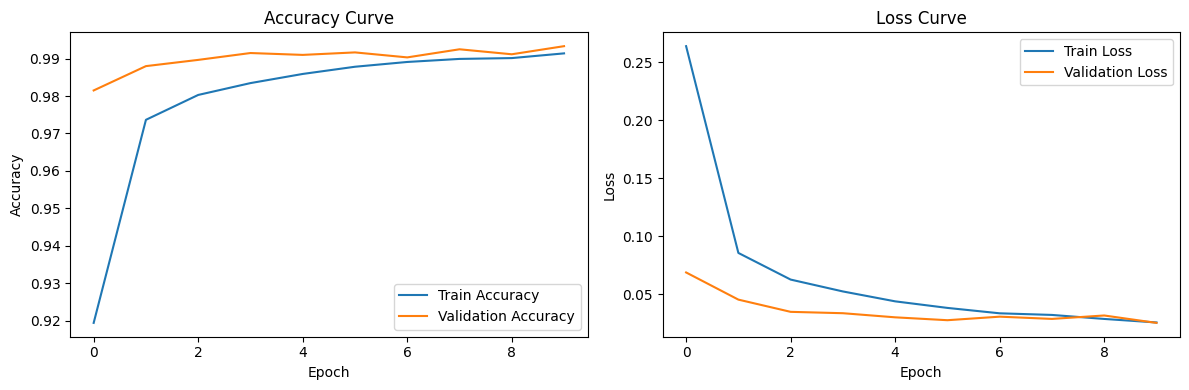

Test Loss: 0.0223
Test Accuracy: 0.9924

Classification Report:
              precision    recall  f1-score   support

           0     0.9959    0.9959    0.9959       980
           1     0.9965    0.9974    0.9969      1135
           2     0.9894    0.9971    0.9932      1032
           3     0.9940    0.9911    0.9926      1010
           4     0.9939    0.9929    0.9934       982
           5     0.9834    0.9944    0.9889       892
           6     0.9979    0.9875    0.9927       958
           7     0.9941    0.9893    0.9917      1028
           8     0.9878    0.9949    0.9913       974
           9     0.9900    0.9832    0.9866      1009

    accuracy                         0.9924     10000
   macro avg     0.9923    0.9924    0.9923     10000
weighted avg     0.9924    0.9924    0.9924     10000



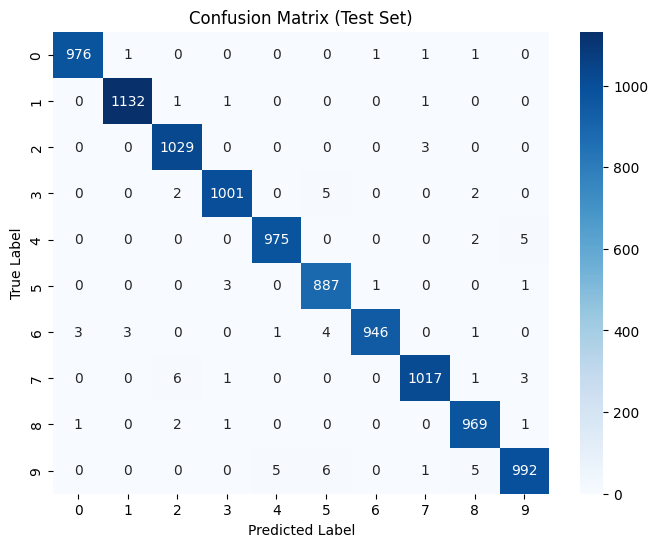

In [6]:
from sklearn.metrics import classification_report, confusion_matrix
import seaborn as sns

# 1. Accuracy and loss curves
plt.figure(figsize=(12, 4))

plt.subplot(1, 2, 1)
plt.plot(history.history["accuracy"], label="Train Accuracy")
plt.plot(history.history["val_accuracy"], label="Validation Accuracy")
plt.xlabel("Epoch")
plt.ylabel("Accuracy")
plt.title("Accuracy Curve")
plt.legend()

plt.subplot(1, 2, 2)
plt.plot(history.history["loss"], label="Train Loss")
plt.plot(history.history["val_loss"], label="Validation Loss")
plt.xlabel("Epoch")
plt.ylabel("Loss")
plt.title("Loss Curve")
plt.legend()

plt.tight_layout()
plt.show()

# 2. Test set evaluation
test_loss, test_acc = model.evaluate(x_test, y_test, verbose=0)
print(f"Test Loss: {test_loss:.4f}")
print(f"Test Accuracy: {test_acc:.4f}")

# 3. Predictions, classification report and confusion matrix
y_pred_probs = model.predict(x_test, verbose=0)
y_pred = np.argmax(y_pred_probs, axis=1)

print("\nClassification Report:")
print(classification_report(y_test_labels, y_pred, digits=4))

cm = confusion_matrix(y_test_labels, y_pred)
plt.figure(figsize=(8, 6))
sns.heatmap(cm, annot=True, fmt="d", cmap="Blues")
plt.xlabel("Predicted Label")
plt.ylabel("True Label")
plt.title("Confusion Matrix (Test Set)")
plt.show()

### Observation

- **Accuracy curve:** training accuracy rises quickly in the first 2 epochs and then slowly climbs to about 99.1%. Validation accuracy stays slightly above training accuracy throughout, which is normal here because Dropout is active during training but turned off during validation.
- **Loss curve:** training loss drops sharply from about 0.26 to below 0.05 within 3 epochs, and validation loss stays low. Both curves end close together, so there is no sign of overfitting.
- **Test Accuracy: 99.24%** and **Test Loss: 0.0223** on 10,000 unseen images. This is very close to the validation accuracy (99.33%), so the model generalizes well.
- **Classification report:** precision, recall and f1-score are above 0.98 for every digit.
  - Best digits: 1 (f1 0.9969) and 0 (f1 0.9959).
  - Weakest digit: 9 (f1 0.9866, recall 0.9832), followed by 5 (f1 0.9889) and 8 (f1 0.9913).
- **Confusion matrix:** the diagonal is very strong. The largest confusions are small, for example 7 predicted as 2 (6 times), 9 predicted as 5 (6 times), 4 and 9 mixed up (5 times each way), and 3 predicted as 5 (5 times). These pairs look similar when handwritten, so the errors make sense.
- Overall only about 76 of 10,000 test images were misclassified.

## Step 7: Predictions and Final Summary

In this final step we will:
- Show 10 random test images with the model's predictions (green title = correct, red title = wrong)
- Show some of the images the model misclassified, to understand where it fails
- Save the trained model so it can be reused later
- Print a short summary of the project

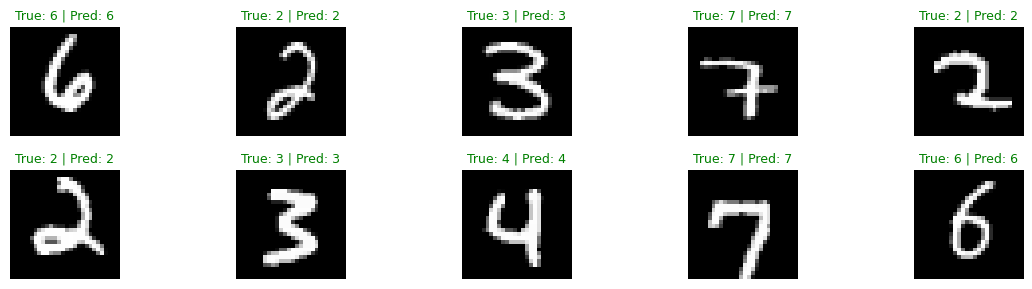

Total misclassified images: 76


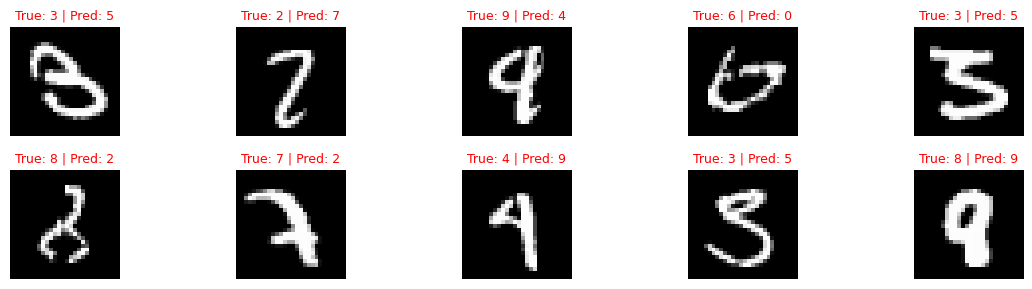

Model saved as mnist_cnn_model.keras

===== FINAL SUMMARY =====
Dataset        : MNIST (60,000 train + 10,000 test)
Model          : CNN (2 Conv + 2 MaxPool + Dropout + 2 Dense)
Parameters     : 225,034
Epochs         : 10
Test Accuracy  : 99.24%
Test Loss      : 0.0223


In [7]:
# 1. Random test predictions
np.random.seed(42)
idx = np.random.choice(len(x_test), 10, replace=False)

plt.figure(figsize=(12, 3))
for i, j in enumerate(idx):
    plt.subplot(2, 5, i + 1)
    plt.imshow(x_test[j].reshape(28, 28), cmap="gray")
    color = "green" if y_pred[j] == y_test_labels[j] else "red"
    plt.title(f"True: {y_test_labels[j]} | Pred: {y_pred[j]}", color=color, fontsize=9)
    plt.axis("off")
plt.tight_layout()
plt.show()

# 2. Misclassified images
wrong = np.where(y_pred != y_test_labels)[0]
print("Total misclassified images:", len(wrong))

plt.figure(figsize=(12, 3))
for i, j in enumerate(wrong[:10]):
    plt.subplot(2, 5, i + 1)
    plt.imshow(x_test[j].reshape(28, 28), cmap="gray")
    plt.title(f"True: {y_test_labels[j]} | Pred: {y_pred[j]}", color="red", fontsize=9)
    plt.axis("off")
plt.tight_layout()
plt.show()

# 3. Save the model
model.save("mnist_cnn_model.keras")
print("Model saved as mnist_cnn_model.keras")

# 4. Final summary
print("\n===== FINAL SUMMARY =====")
print("Dataset        : MNIST (60,000 train + 10,000 test)")
print("Model          : CNN (2 Conv + 2 MaxPool + Dropout + 2 Dense)")
print("Parameters     : 225,034")
print("Epochs         :", 10)
print(f"Test Accuracy  : {test_acc * 100:.2f}%")
print(f"Test Loss      : {test_loss:.4f}")

### Observation

- **Random test predictions:** all 10 randomly chosen test images were predicted correctly (green titles), including some with unusual handwriting styles such as the "7" with a crossbar and the looped "2".
- **Misclassified images:** the model made 76 mistakes out of 10,000 test images, which matches the confusion matrix (about 0.76% error).
- The misclassified digits are genuinely hard cases. For example, a "9" that looks like a "4", a "7" drawn like a "2", and an "8" with a broken, curly shape. Many of these would be difficult even for a human to read.
- The same confusing pairs seen in the confusion matrix (3 and 5, 4 and 9, 2 and 7) appear again here, which confirms that the errors come from similar-looking shapes.
- **Model saved** as `mnist_cnn_model.keras`, so it can be reloaded later without retraining.
- **Final summary:** MNIST (60,000 train + 10,000 test), CNN with 225,034 parameters, 10 epochs, **Test Accuracy 99.24%**, Test Loss 0.0223.

## Conclusion

In this project we built a Convolutional Neural Network to recognize handwritten digits (0 to 9) from the MNIST dataset.

- The data was normalized, reshaped to (28, 28, 1) and the labels were one-hot encoded.
- The CNN (2 Conv layers, 2 MaxPooling layers, Dropout and 2 Dense layers) was trained for 10 epochs.
- The model reached **99.24% accuracy** on 10,000 unseen test images, with only 76 misclassifications.
- Training and validation curves stayed close together, so the model generalizes well without overfitting.
- Remaining errors mostly come from digits that look alike when handwritten (3/5, 4/9, 2/7).

**Possible future improvements:**
- Data augmentation (small rotations, shifts and zoom) to handle unusual handwriting
- A deeper CNN with Batch Normalization
- Extending to the EMNIST dataset to recognize letters as well as digits
- Using a CRNN to recognize full words or sentences